In [1]:
%pip install -q biopython pandas matplotlib seaborn requests
!apt-get -qq update
!apt-get -qq install clustalo

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package libargtable2-0.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../libargtable2-0_13-2_amd64.deb ...
Unpacking libargtable2-0 (13-2) ...
Selecting previously unselected package clustalo.
Preparing to unpack .../clustalo_1.2.4-8build1_amd64.deb ...
Unpacking clustalo (1.2.4-8build1) ...
Setting up libargtable2-0 (13-2) ...
Setting up clustalo (1.2.4-8build1) ...
Processing triggers for libc-bin (2.39-0ubuntu8.9) ...
/sbin/ldconfig.real: /usr/local/lib/libtcm_debug.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtcm.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_loader.so.0 is not a symbolic link

/s

In [2]:
# Downloading the hemoglobin beta sequences
import requests
import pandas as pd
from Bio import SeqIO
from io import StringIO
from pathlib import Path
from datetime import date

Path("data").mkdir(exist_ok=True)

proteins = {
    "Human": "P68871",
    "Chimpanzee": "P68873",
    "Cow": "P02070",
    "Sheep": "P02075",
    "Chicken": "P02112"
}

records = []
summary = []

for animal, accession in proteins.items():
    url = f"https://rest.uniprot.org/uniprotkb/{accession}.fasta"
    response = requests.get(url, timeout=60)
    response.raise_for_status()

    record = SeqIO.read(StringIO(response.text), "fasta")
    original_description = record.description

    Path(f"data/{accession}.fasta").write_text(response.text)



    record.id = animal
    record.description = accession
    records.append(record)

    summary.append({
        "Animal": animal,
        "Accession": accession,
        "Length": len(record.seq),
        "Description": original_description,
        "Download_date": str(date.today())
    })

SeqIO.write(records, "data/hemoglobin_beta.fasta", "fasta")

sequence_table = pd.DataFrame(summary)
sequence_table.to_csv("data/sequence_info.csv", index=False)

display(sequence_table[["Animal", "Accession", "Length"]])
print("Saved all five sequences.")

,Animal,Accession,Length
0,Human,P68871,147
1,Chimpanzee,P68873,147
2,Cow,P02070,145
3,Sheep,P02075,145
4,Chicken,P02112,147


Saved all five sequences.


In [3]:
# Aligning the five protein sequences
import subprocess
from Bio import AlignIO

result = subprocess.run(
    [
        "clustalo",
        "-i", "data/hemoglobin_beta.fasta",
        "-o", "data/hemoglobin_aligned.fasta",
        "--outfmt=fasta",
        "--force"
    ],
    capture_output=True,
    text=True
)

if result.returncode != 0:
    raise RuntimeError(result.stderr)

alignment = AlignIO.read("data/hemoglobin_aligned.fasta", "fasta")

print("Number of sequences:", len(alignment))
print("Alignment length:", alignment.get_alignment_length())

for record in alignment:
    print(f"{record.id:12} {record.seq}")

Number of sequences: 5
Alignment length: 147
Human        MVHLTPEEKSAVTALWGKVNVDEVGGEALGRLLVVYPWTQRFFESFGDLSTPDAVMGNPKVKAHGKKVLGAFSDGLAHLDNLKGTFATLSELHCDKLHVDPENFRLLGNVLVCVLAHHFGKEFTPPVQAAYQKVVAGVANALAHKYH
Chimpanzee   MVHLTPEEKSAVTALWGKVNVDEVGGEALGRLLVVYPWTQRFFESFGDLSTPDAVMGNPKVKAHGKKVLGAFSDGLAHLDNLKGTFATLSELHCDKLHVDPENFRLLGNVLVCVLAHHFGKEFTPPVQAAYQKVVAGVANALAHKYH
Cow          --MLTAEEKAAVTAFWGKVKVDEVGGEALGRLLVVYPWTQRFFESFGDLSTADAVMNNPKVKAHGKKVLDSFSNGMKHLDDLKGTFAALSELHCDKLHVDPENFKLLGNVLVVVLARNFGKEFTPVLQADFQKVVAGVANALAHRYH
Sheep        --MLTAEEKAAVTGFWGKVKVDEVGAEALGRLLVVYPWTQRFFEHFGDLSNADAVMNNPKVKAHGKKVLDSFSNGMKHLDDLKGTFAQLSELHCDKLHVDPENFRLLGNVLVVVLARHHGNEFTPVLQADFQKVVAGVANALAHKYH
Chicken      MVHWTAEEKQLITGLWGKVNVAECGAEALARLLIVYPWTQRFFASFGNLSSPTAILGNPMVRAHGKKVLTSFGDAVKNLDNIKNTFSQLSELHCDKLHVDPENFRLLGDILIIVLAAHFSKDFTPECQAAWQKLVRVVAHALARKYH


In [4]:
# Calculate pairwise percent identity
from itertools import combinations

animals = [record.id for record in alignment]
identity_table = pd.DataFrame(
    100.0, index=animals, columns=animals
)

pair_results = []

for first, second in combinations(alignment, 2):
    positions = [
        (a, b)
        for a, b in zip(str(first.seq), str(second.seq))
        if a != "-" and b != "-"
    ]

    matches = sum(a == b for a, b in positions)
    identity = matches / len(positions) * 100

    identity_table.loc[first.id, second.id] = identity
    identity_table.loc[second.id, first.id] = identity

    pair_results.append({
        "Animal 1": first.id,
        "Animal 2": second.id,
        "Matching positions": matches,
        "Compared positions": len(positions),
        "Percent identity": identity
    })

pair_table = pd.DataFrame(pair_results)

identity_table.to_csv("data/percent_identity_matrix.csv")
pair_table.to_csv("data/pairwise_comparisons.csv", index=False)

display(pair_table.round(2))

,Animal 1,Animal 2,Matching positions,Compared positions,Percent identity
0,Human,Chimpanzee,147,147,100.00
1,Human,Cow,122,145,84.14
2,Human,Sheep,119,145,82.07
3,Human,Chicken,102,147,69.39
4,Chimpanzee,Cow,122,145,84.14
5,Chimpanzee,Sheep,119,145,82.07
6,Chimpanzee,Chicken,102,147,69.39
7,Cow,Sheep,135,145,93.10
8,Cow,Chicken,92,145,63.45
9,Sheep,Chicken,95,145,65.52


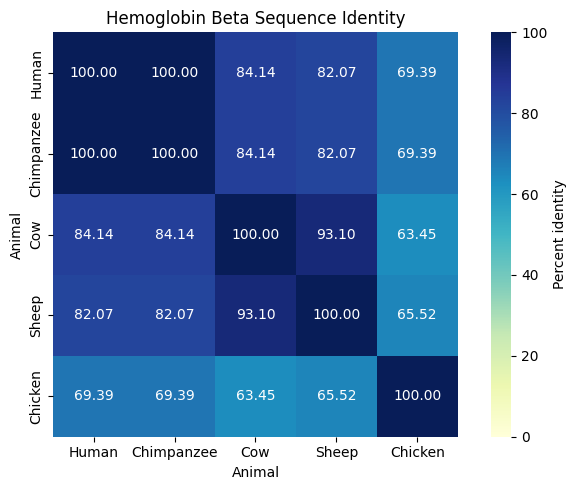

In [5]:
# Percent identity heatmap
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

Path("figures").mkdir(exist_ok=True)

plt.figure(figsize=(7, 5))

sns.heatmap(
    identity_table,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    square=True,
    cbar_kws={"label": "Percent identity"}
)

plt.title("Hemoglobin Beta Sequence Identity")
plt.xlabel("Animal")
plt.ylabel("Animal")
plt.tight_layout()

plt.savefig("figures/hemoglobin_identity_heatmap.png", dpi=300)
plt.show()

In [6]:
# Compare conserved positions
sequences = {
    record.id: str(record.seq)
    for record in alignment
}

mammals = ["Human", "Chimpanzee", "Cow", "Sheep"]
all_animals = mammals + ["Chicken"]

position_rows = []

for i in range(alignment.get_alignment_length()):
    residues = [sequences[animal][i] for animal in all_animals]



    if "-" in residues:
        continue

    row = {"Alignment position": i + 1}

    for animal in all_animals:
        row[animal] = sequences[animal][i]

    row["Conserved in mammals"] = len(
        {sequences[animal][i] for animal in mammals}
    ) == 1

    row["Conserved in all five"] = len(set(residues)) == 1
    position_rows.append(row)

position_table = pd.DataFrame(position_rows)
total_positions = len(position_table)

conservation_summary = pd.DataFrame({
    "Group": ["Four mammals", "All five animals"],
    "Compared positions": [total_positions, total_positions],
    "Conserved positions": [
        position_table["Conserved in mammals"].sum(),
        position_table["Conserved in all five"].sum()
    ]
})

conservation_summary["Percent conserved"] = (
    conservation_summary["Conserved positions"]
    / conservation_summary["Compared positions"] * 100
)

position_table.to_csv("data/conservation_by_position.csv", index=False)
conservation_summary.to_csv("data/conservation_summary.csv", index=False)

display(conservation_summary.round(2))

,Group,Compared positions,Conserved positions,Percent conserved
0,Four mammals,145,116,80.00
1,All five animals,145,86,59.31


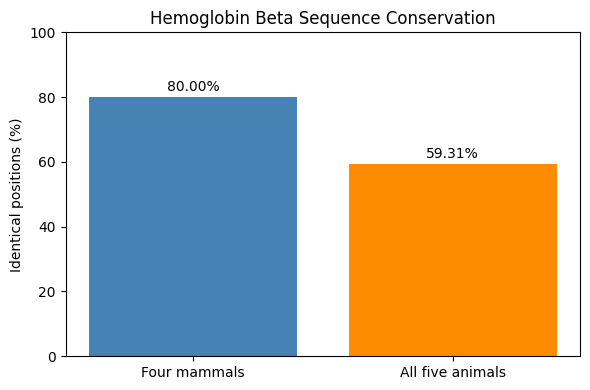

In [7]:
# Plotting the conservation comparison
plt.figure(figsize=(6, 4))

bars = plt.bar(
    conservation_summary["Group"],
    conservation_summary["Percent conserved"],
    color=["steelblue", "darkorange"]
)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

plt.ylabel("Identical positions (%)")
plt.title("Hemoglobin Beta Sequence Conservation")
plt.ylim(0, 100)
plt.tight_layout()

plt.savefig("figures/hemoglobin_conservation.png", dpi=300)
plt.show()

In [8]:
# Check a calculation and record software versions
import sys
import Bio
import matplotlib
import seaborn
import requests

# human versus cow
human = sequences["Human"]
cow = sequences["Cow"]

matches = 0
compared = 0

for i in range(len(human)):
    if human[i] != "-" and cow[i] != "-":
        compared += 1
        if human[i] == cow[i]:
            matches += 1

percent = matches / compared * 100
assert abs(percent - identity_table.loc["Human", "Cow"]) < 0.000001

print(f"Human vs Cow: {matches}/{compared} × 100 = {percent:.2f}%")
print("Calculation agrees with the similarity table.")

versions = (
    f"Python: {sys.version.split()[0]}\n"
    f"Biopython: {Bio.__version__}\n"
    f"Pandas: {pd.__version__}\n"
    f"Matplotlib: {matplotlib.__version__}\n"
    f"Seaborn: {seaborn.__version__}\n"
    f"Requests: {requests.__version__}\n"
    f"Clustal Omega: "
    f"{subprocess.check_output(['clustalo', '--version'], text=True).strip()}\n"
)

Path("software_versions.txt").write_text(versions)
print("\n" + versions)

Human vs Cow: 122/145 × 100 = 84.14%
Calculation agrees with the similarity table.

Python: 3.13.18
Biopython: 1.88
Pandas: 2.2.3
Matplotlib: 3.10.0
Seaborn: 0.13.2
Requests: 2.32.4
Clustal Omega: 1.2.4



In [9]:
import zipfile
from pathlib import Path
from google.colab import files

with zipfile.ZipFile("hemoglobin_project_files.zip", "w") as archive:
    for folder in ["data", "figures"]:
        for file in Path(folder).rglob("*"):
            if file.is_file():
                archive.write(file)

    archive.write("software_versions.txt")

files.download("hemoglobin_project_files.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>